# Módulo 2 — Segmentación y Morfología Matemática de la Pupila
**PupilTrack — PSIB, ITBA (2do Q 2026) — Grupo 5**

Se comparan los métodos de la guía (Otsu, K-Means con K = 2 a 5, Snakes y Watershed), más region growing como referencia, sobre frames reales. Después se aplica morfología matemática para limpiar la máscara, y **se valida cada método contra una referencia anotada a mano** en 8 frames de A1, A2 y B1 (Dice e IoU).

**Referencia manual** (`anotaciones/anotaciones_manuales.csv`): en cada frame se marcaron a mano, sobre el frame ampliado con una grilla de 5 px, los extremos izquierdo, derecho, superior e inferior del borde pupilar. La pupila de referencia es la elipse que pasa por esos cuatro puntos. Los frames cubren penumbra y luz, reflejo corneal, velo de reflejo sobre la pupila y desenfoque.

In [1]:
VIDEO_PATH = "../data/A1.mov"   # registro con el que se desarrolla el módulo
FRAME_INDICE = 700              # frame de trabajo (None = el del medio)


## Setup

In [2]:
import sys, os
sys.path.append(os.path.abspath(".."))

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pupiltrack import acquisition as acq
from pupiltrack import preprocessing as pp
from pupiltrack import filtering as filt
from pupiltrack import edges_frequency as ef
from pupiltrack import segmentation as seg
from pupiltrack import morphology as morf
from pupiltrack import texture as tex
from pupiltrack import temporal as tmp
from pupiltrack import compression as comp

np.random.seed(0)
pd.set_option("display.width", 200)

def mostrar_varias(imagenes, titulos, cmap="gray", ancho=3.2, filas=1):
    cols = int(np.ceil(len(imagenes) / filas))
    fig, ax = plt.subplots(filas, cols, figsize=(ancho * cols, ancho * filas))
    ax = np.atleast_1d(ax).ravel()
    for a, im, t in zip(ax, imagenes, titulos):
        a.imshow(im if im.ndim == 3 else im, cmap=None if im.ndim == 3 else cmap)
        a.set_title(t, fontsize=9); a.axis("off")
    for a in ax[len(imagenes):]: a.axis("off")
    plt.tight_layout(); plt.show()

def generar_ojo_sintetico(size=300):
    img = np.full((size, size, 3), 230, dtype=np.uint8)
    centro = (size // 2, size // 2)
    cv2.circle(img, centro, 110, (180, 200, 210), -1)
    cv2.circle(img, centro, 70, (90, 60, 40), -1)
    cv2.circle(img, centro, 30, (10, 10, 10), -1)
    cv2.circle(img, (centro[0] + 12, centro[1] - 12), 6, (255, 255, 255), -1)
    return img
from pupiltrack import evaluacion as ev

## Frame de trabajo
ROI cuadrada centrada en la pupila, localizada **automáticamente** (sin usar la anotación).

Frame 700 | ROI 183x183 px desde (270, 143) | radio estimado 23.0 px


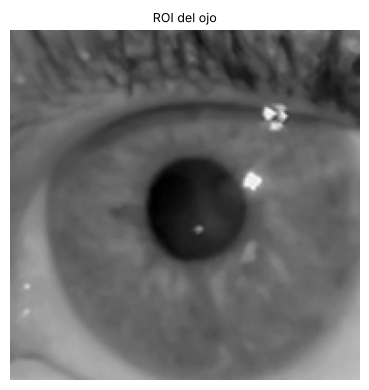

In [3]:
if VIDEO_PATH and os.path.exists(VIDEO_PATH):
    frame_completo = ev.leer_frame(VIDEO_PATH, FRAME_INDICE)
    gris, (x0, y0), centro, r_est = ev.roi_automatica_pupila(frame_completo)
    print(f"Frame {FRAME_INDICE} | ROI {gris.shape[1]}x{gris.shape[0]} px desde ({x0}, {y0}) | radio estimado {r_est:.1f} px")
else:
    frame_completo = generar_ojo_sintetico()
    gris = cv2.cvtColor(frame_completo, cv2.COLOR_BGR2GRAY)
    x0 = y0 = 0; centro = np.array([150., 150.]); r_est = 30.
    print("Sin video: imagen sintética")
mostrar_varias([gris], ["ROI del ojo"], ancho=4)

## 2.1 — Algoritmos de segmentación

### Umbralización automática de Otsu

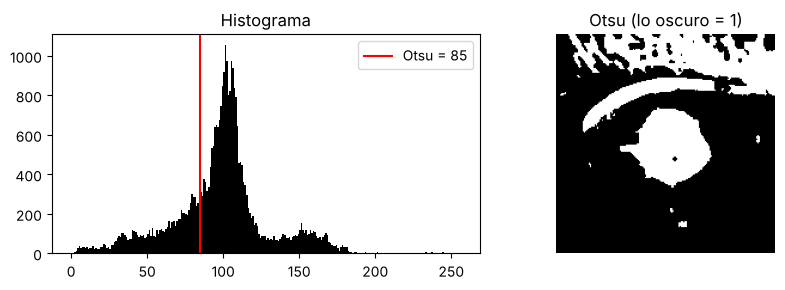

In [4]:
m_otsu, t_otsu = seg.umbral_otsu(gris)
otsu = cv2.bitwise_not(m_otsu)
plt.figure(figsize=(9, 3))
plt.subplot(1, 2, 1); plt.hist(gris.ravel(), bins=256, range=(0, 256), color="k"); plt.axvline(t_otsu, c="r", label=f"Otsu = {t_otsu:.0f}"); plt.legend(); plt.title("Histograma")
plt.subplot(1, 2, 2); plt.imshow(otsu, cmap="gray"); plt.title("Otsu (lo oscuro = 1)"); plt.axis("off")
plt.tight_layout(); plt.show()

### K-Means (K = 2 a 5), agrupando por intensidad
Se toma como pupila el clúster más oscuro.

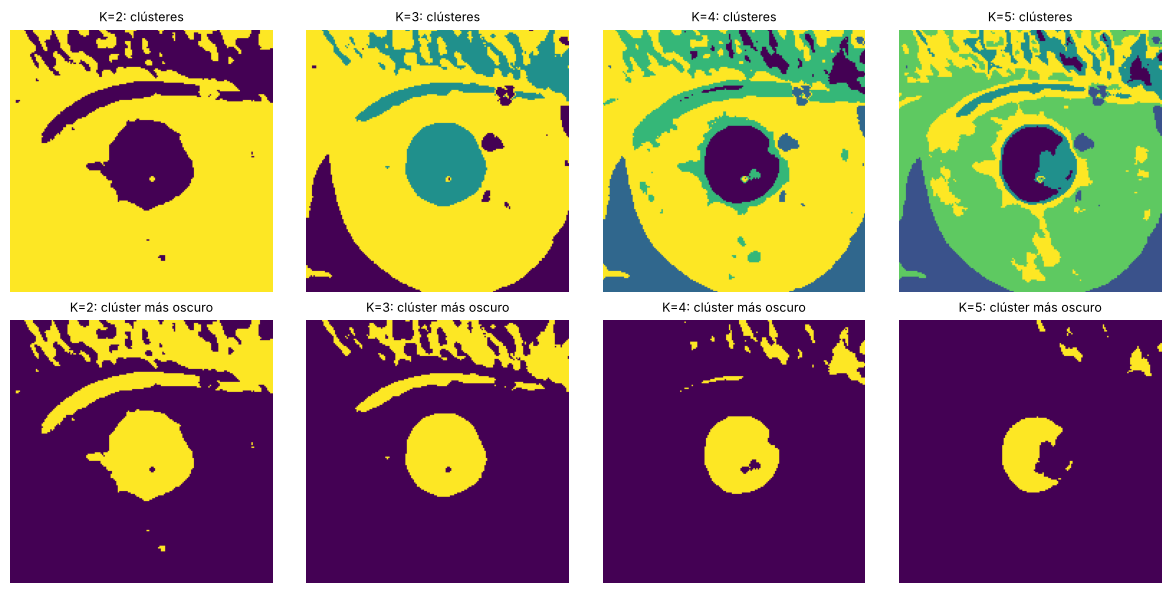

In [5]:
km = {}
for k in range(2, 6):
    cv2.setRNGSeed(0)
    et, ce = seg.segmentar_kmeans(gris, k=k)
    km[k] = (et, seg.mascara_desde_kmeans(et, ce, cluster_mas_oscuro=True))
mostrar_varias([km[k][0] for k in km] + [km[k][1] for k in km],
               [f"K={k}: clústeres" for k in km] + [f"K={k}: clúster más oscuro" for k in km], cmap="viridis", filas=2, ancho=3)

### Contornos activos (Snakes)
Contorno inicial: círculo de 1,5 veces el radio estimado alrededor de la pupila. El snake se deforma minimizando una energía interna (α: elasticidad, β: rigidez) más la externa (gradiente de la imagen) hasta el borde del esfínter pupilar.

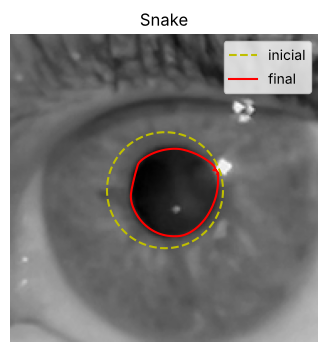

In [6]:
suave = cv2.GaussianBlur(gris, (0, 0), 2)
ini = seg.contorno_inicial_circular(centro, 1.5 * r_est, 200)
fin = seg.snake_activo(suave, ini, alpha=0.015, beta=10, gamma=0.001)
snake = seg.contorno_a_mascara(fin, gris.shape)
plt.figure(figsize=(4, 4)); plt.imshow(gris, cmap="gray")
plt.plot(ini[:, 1], ini[:, 0], "--y", label="inicial"); plt.plot(fin[:, 1], fin[:, 0], "-r", label="final")
plt.legend(); plt.axis("off"); plt.title("Snake"); plt.show()

### Watershed (cuenca hidrográfica)
Dos variantes:
- **Por transformada de distancia** (la clásica de clase): Otsu → distancia → máximos locales como marcadores → inundación.
- **Por gradiente con marcadores** (la que usa el pipeline): marcador "pupila" en el punto más oscuro cercano al centro y marcador "fondo" a más de 1,6 radios. Se inunda la **magnitud del gradiente**, así que la línea divisoria cae en el borde pupila/iris de máximo contraste, y el reflejo corneal queda separado de la pupila.

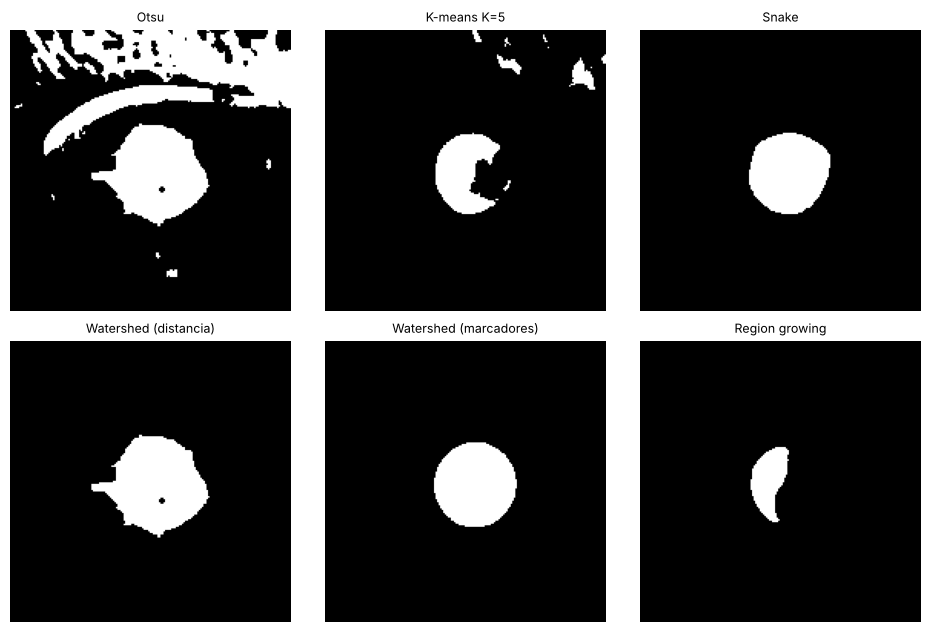

In [7]:
ws_dist = seg.segmentar_watershed(gris)
ws_marc = tmp.refinar_borde_watershed(gris, centro, r_est)
rg = tmp.segmentar_frame(gris, "region_growing", solo_pupila=False)
mostrar_varias([otsu, km[5][1], snake, ws_dist, ws_marc, rg],
               ["Otsu", "K-means K=5", "Snake", "Watershed (distancia)", "Watershed (marcadores)", "Region growing"], filas=2, ancho=3.2)

## 2.2 — Morfología matemática para limpieza de máscara
Se muestra sobre la máscara de **K-means K = 5**, que tiene los defectos típicos: pestañas, sombras, huecos por el reflejo y fragmentos sueltos.

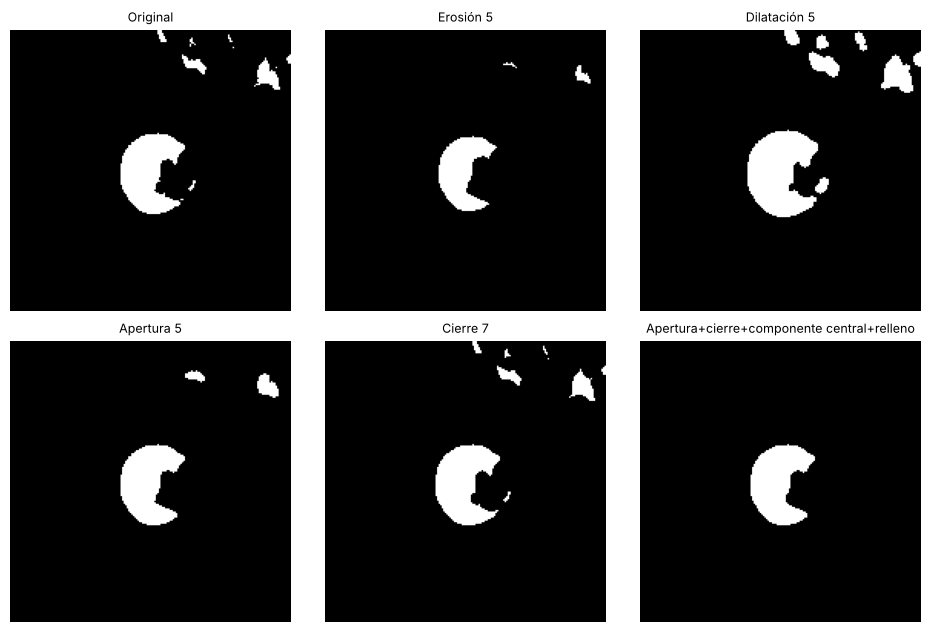

In [8]:
base = km[5][1]
ee = lambda t: cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (t, t))
ops = {"Original": base, "Erosión 5": cv2.erode(base, ee(5)), "Dilatación 5": cv2.dilate(base, ee(5)),
       "Apertura 5": morf.apertura(base, 5), "Cierre 7": morf.cierre(base, 7),
       "Apertura+cierre+componente central+relleno": ev.limpiar(base, centro, "apertura+cierre+relleno")}
mostrar_varias(list(ops.values()), list(ops), filas=2, ancho=3.2)

### Esqueletización

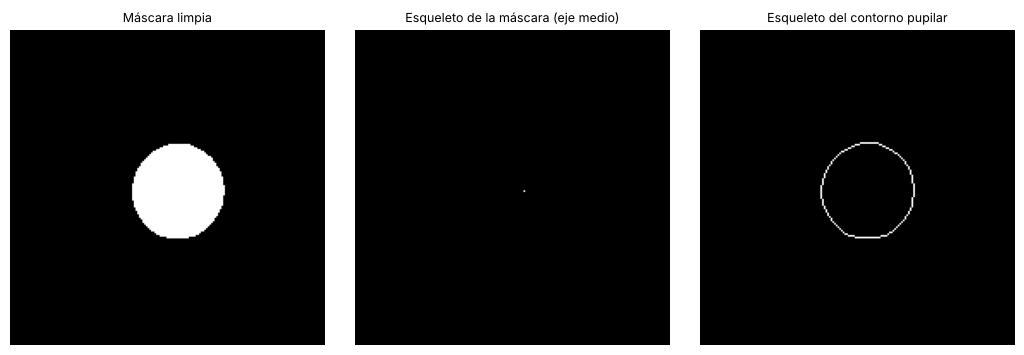

In [9]:
limpia = ev.limpiar(ws_marc, centro, "apertura+cierre+relleno")
contorno = cv2.morphologyEx(limpia, cv2.MORPH_GRADIENT, ee(3))
mostrar_varias([limpia, morf.esqueletizar(limpia), morf.esqueletizar(contorno)],
               ["Máscara limpia", "Esqueleto de la máscara (eje medio)", "Esqueleto del contorno pupilar"], ancho=3.5)

El esqueleto de una región casi circular colapsa a un punto o un segmento corto (el eje medio), que da el centro de la pupila. El esqueleto del **contorno** da una curva de 1 px de ancho: el perímetro pupilar, útil para medir el perímetro y la regularidad del borde.

## Validación contra la referencia manual (Dice e IoU)
Para cada uno de los 8 frames anotados se segmenta la ROI con cada método y se compara con la elipse de referencia, tanto con la máscara **cruda** como **limpia** (apertura 5 + cierre 7 + componente central + relleno de huecos).

In [10]:
anot = ev.cargar_anotaciones()
display(anot[["video", "frame", "x_izq", "x_der", "y_sup", "y_inf", "diametro_manual_px", "nota"]].round(1))

metodos = ["Otsu", "K-means K=2", "K-means K=3", "K-means K=4", "K-means K=5", "Snake",
           "Watershed (distancia)", "Watershed (marcadores)", "Region growing"]
filas, ejemplos = [], {}
for _, f in anot.iterrows():
    ruta = os.path.join("..", "data", f"{f.video}.mov")
    if not os.path.exists(ruta):
        print(f"(falta {ruta}: se saltea)"); continue
    fr = ev.leer_frame(ruta, f.frame)
    roi, off, c, r = ev.roi_automatica_pupila(fr)
    ref = ev.mascara_referencia(f, roi.shape, off)
    for met in metodos:
        k = int(met[-1]) if met.startswith("K-means") else 3
        cruda = ev.segmentar_metodo(roi, met, c, r, k)
        limpia_m = ev.limpiar(cruda, c, "apertura+cierre+relleno")
        for var, m in [("cruda", cruda), ("limpia", limpia_m)]:
            filas.append({"video": f.video, "frame": f.frame, "metodo": met, "mascara": var, **ev.metricas(m, ref)})
        if (f.video, f.frame) == ("A1", 120):
            ejemplos[met] = limpia_m
    if (f.video, f.frame) == ("A1", 120):
        ejemplo_roi, ejemplo_ref = roi, ref
dice = pd.DataFrame(filas)
resumen = dice.groupby(["metodo", "mascara"])[["dice", "iou"]].mean().unstack().round(3)
resumen = resumen.sort_values(("dice", "limpia"), ascending=False)
display(resumen)

,video,frame,x_izq,x_der,y_sup,y_inf,diametro_manual_px,nota
0,A1,120,359,435,226,303,76.5,penumbra; velo gris del reflejo sobre la mitad...
1,A1,331,360,436,207,282,75.5,penumbra; velo gris del reflejo sobre la mitad...
2,A1,700,341,393,210,263,52.5,con luz; borde nitido
3,A1,1300,330,384,203,260,55.5,con luz; borde nitido
4,A2,118,505,563,268,330,60.0,penumbra; imagen desenfocada; borde poco definido
5,A2,1000,512,569,314,370,56.5,con luz; reflejo corneal arriba
6,B1,200,360,414,217,269,53.0,con luz; reflejo corneal arriba a la izquierda
7,B1,1000,363,430,190,255,66.0,penumbra; velo gris arriba a la izquierda dent...


dice           iou       
mascara                 cruda limpia  cruda limpia
metodo                                            
Watershed (marcadores)  0.940  0.940  0.889  0.889
K-means K=5             0.510  0.778  0.358  0.661
Snake                   0.764  0.764  0.685  0.686
Region growing          0.711  0.707  0.573  0.568
K-means K=4             0.478  0.665  0.337  0.571
K-means K=3             0.318  0.430  0.196  0.330
Watershed (distancia)   0.374  0.375  0.280  0.281
K-means K=2             0.203  0.254  0.117  0.176
Otsu                    0.200  0.251  0.115  0.172

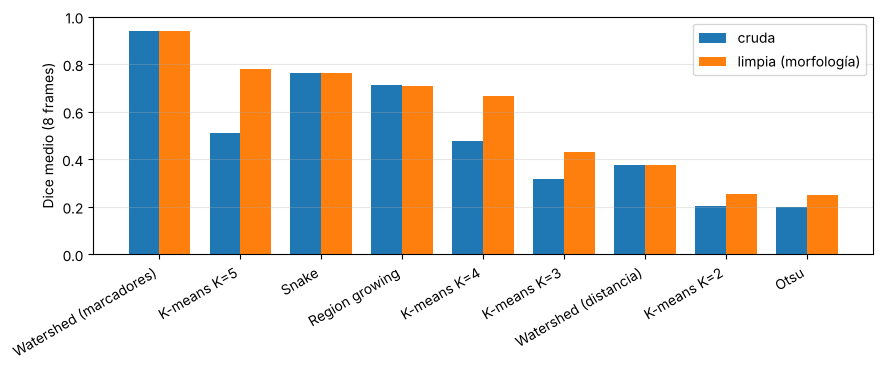

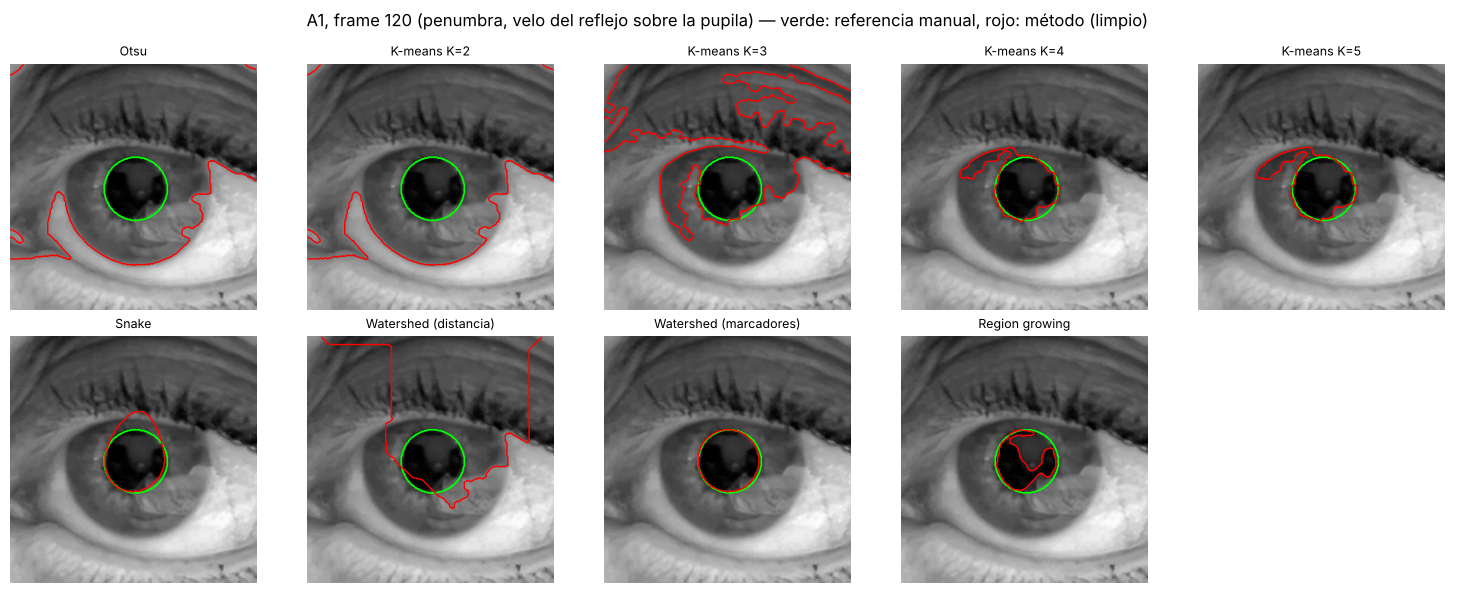

In [11]:
fig, ax = plt.subplots(figsize=(9, 3.8))
orden = resumen.index
x = np.arange(len(orden)); w = 0.38
ax.bar(x - w / 2, resumen[("dice", "cruda")], w, label="cruda")
ax.bar(x + w / 2, resumen[("dice", "limpia")], w, label="limpia (morfología)")
ax.set_xticks(x, orden, rotation=30, ha="right"); ax.set_ylabel("Dice medio (8 frames)"); ax.set_ylim(0, 1); ax.legend(); ax.grid(axis="y", alpha=.3)
plt.tight_layout(); plt.show()

if ejemplos:
    fig, ax = plt.subplots(2, 5, figsize=(15, 6))
    for a, (met, m) in zip(ax.ravel(), list(ejemplos.items())[:9]):
        a.imshow(ejemplo_roi, cmap="gray")
        a.contour(ejemplo_ref, [127], colors="lime", linewidths=1.2)
        a.contour(m, [127], colors="red", linewidths=1)
        a.set_title(met, fontsize=9); a.axis("off")
    ax.ravel()[-1].axis("off")
    plt.suptitle("A1, frame 120 (penumbra, velo del reflejo sobre la pupila) — verde: referencia manual, rojo: método (limpio)")
    plt.tight_layout(); plt.show()

In [12]:
print("Dice por frame (máscara limpia):")
display(dice[dice.mascara == "limpia"].pivot_table(index=["video", "frame"], columns="metodo", values="dice").round(2)[list(orden)])

Dice por frame (máscara limpia):


metodo       Watershed (marcadores)  K-means K=5  Snake  Region growing  K-means K=4  K-means K=3  Watershed (distancia)  K-means K=2  Otsu
video frame                                                                                                                                
A1    120                      0.97         0.85   0.87            0.70         0.86         0.24                   0.25         0.14  0.14
      331                      0.91         0.78   0.90            0.62         0.81         0.27                   0.32         0.19  0.19
      700                      0.97         0.76   0.95            0.51         0.95         0.93                   0.84         0.86  0.84
      1300                     0.96         0.94   0.95            0.48         0.94         0.92                   0.81         0.35  0.35
A2    118                      0.97         0.72   0.71            0.89         0.15         0.12                   0.00         0.09  0.09
      1000                     0.91         0.40   0.91            0.71         0.36         0.32                   0.00         0.14  0.14
B1    200                      0.90         0.88   0.00            0.88         0.35         0.33                   0.23         0.13  0.13
      1000                     0.93         0.89   0.83            0.86         0.90         0.32                   0.54         0.13  0.13

### Combinación óptima de operaciones morfológicas
Sobre los tres métodos más usados, se comparan distintas secuencias de limpieza contra la referencia.

In [13]:
variantes = ["cruda", "apertura", "cierre", "apertura+cierre", "apertura+cierre+relleno", "apertura+cierre+relleno+convexa"]
filas = []
for _, f in anot.iterrows():
    ruta = os.path.join("..", "data", f"{f.video}.mov")
    if not os.path.exists(ruta): continue
    fr = ev.leer_frame(ruta, f.frame)
    roi, off, c, r = ev.roi_automatica_pupila(fr)
    ref = ev.mascara_referencia(f, roi.shape, off)
    for met in ["K-means K=5", "Region growing", "Watershed (marcadores)"]:
        cruda = ev.segmentar_metodo(roi, met, c, r, 5)
        for var in variantes:
            m = cruda if var == "cruda" else ev.limpiar(cruda, c, var)
            filas.append({"metodo": met, "variante": var, **ev.metricas(m, ref)})
morfo = pd.DataFrame(filas).groupby(["variante", "metodo"])["dice"].mean().unstack().loc[variantes].round(3)
display(morfo)

metodo,K-means K=5,Region growing,Watershed (marcadores)
variante,,,
cruda,0.510,0.711,0.940
apertura,0.778,0.703,0.940
cierre,0.770,0.712,0.940
apertura+cierre,0.780,0.707,0.940
apertura+cierre+relleno,0.778,0.707,0.940
apertura+cierre+relleno+convexa,0.786,0.789,0.938


## Conclusiones del Módulo 2

**Comparación de métodos (Dice medio contra la referencia manual, 8 frames):**

| Método | Dice (máscara limpia) | Por qué |
|---|---|---|
| **Watershed con marcadores (gradiente)** | **0,94** | El borde cae donde el gradiente pupila/iris es máximo, sin depender de un umbral. Es el único que supera 0,90 en **todos** los frames: penumbra, luz, velo del reflejo y desenfoque. |
| K-means K = 5 | 0,78 | Con 5 clústeres, el más oscuro ya es solo la pupila; con K = 2–3 el clúster oscuro incluye iris, pestañas y sombras. Falla en A2 con luz (0,40), donde la pupila se funde con las pestañas. |
| Snake | 0,76 | Converge bien cuando el borde es nítido (0,95 con luz), pero depende del contorno inicial y de los parámetros. En B1 (frame 200) colapsa (0,00), atraído por el reflejo corneal pegado a la pupila. |
| Region growing | 0,71 | Con tolerancia fija deja afuera la parte de la pupila cubierta por el velo del reflejo, o se escapa por las pestañas. |
| K-means K = 3 / 4 | 0,43 / 0,67 | Mejora al aumentar K. |
| Watershed por distancia | 0,38 | Parte de la máscara de Otsu: hereda su error y separa por forma, no por contraste. |
| Otsu, K-means K = 2 | 0,25 | Un umbral **global** separa "oscuro" de "claro" en toda la ROI: junta pupila, iris, pestañas y piel en sombra. Solo funciona con luz y el iris claro (0,84–0,86 en A1, frame 700). |

**Morfología (2.2):**
- La **apertura** (erosión + dilatación) elimina los fragmentos chicos de pestañas y ruido. La **erosión** sola achica la pupila y la **dilatación** sola la agranda y une fragmentos.
- El **cierre** (dilatación + erosión) rellena los huecos chicos, como el del reflejo corneal dentro de la pupila.
- Sobre K-means K = 5, la limpieza sube el Dice de **0,51 a 0,78**. La mejora la aporta sobre todo quedarse con la **componente conexa central** (descarta pestañas y sombras); la apertura y el cierre afinan.
- El **relleno de huecos** no cambia el Dice promedio, pero es necesario para medir bien el área cuando el reflejo queda dentro de la pupila. La **envolvente convexa** corrige el caso en que el reflejo "muerde" el borde: sube region growing de 0,71 a 0,79.
- **Combinación óptima:** apertura (5) → cierre (7) → componente conexa central → relleno de huecos, más la envolvente convexa si hay reflejo en el borde. Con la watershed con marcadores la limpieza casi no cambia nada (0,94 → 0,94), porque ya entrega una región cerrada y sin fragmentos.

**Método elegido para el pipeline:** la watershed con marcadores sobre el gradiente, con elipse ajustada al borde visible. Es la que usa `temporal.py` para medir la pupila en cada frame.

**Limitación de la referencia:** las anotaciones manuales tienen una incertidumbre de ±1–2 px por punto (lectura sobre una grilla de 5 px en un borde algo difuso), y la elipse por 4 extremos no representa pupilas irregulares. Un Dice de 0,94 equivale a un error de borde del orden de esa incertidumbre.